# Maternal Health Risk Classification: An Honest Evaluation

**Goal:** predict a pregnant woman's health risk level (**low / mid / high**) from six routine vital signs, and measure how well that works on patients the model has **never seen**.

This notebook focuses on three questions:

1. **Can we trust the evaluation?** The dataset contains many repeated records. If the same record lands in both the training and test sets, the model is graded on answers it has already memorized.
2. **Does the model catch high risk cases?** Missing a high risk pregnancy is far more costly than a false alarm, so recall on the *high risk* class is tracked alongside overall performance.
3. **What drives the predictions, and where does the model fail?**

**Dataset:** [Maternal Health Risk Data Set](https://www.kaggle.com/datasets/csafrit2/maternal-health-risk-data) (1,014 records collected from hospitals and community clinics in Bangladesh through an IoT based monitoring system).

| Feature | Description | Unit |
|---|---|---|
| Age | Age during pregnancy | years |
| SystolicBP | Upper blood pressure value | mmHg |
| DiastolicBP | Lower blood pressure value | mmHg |
| BS | Blood glucose | mmol/L |
| BodyTemp | Body temperature | °F |
| HeartRate | Resting heart rate | bpm |
| RiskLevel | Target: low / mid / high risk | |

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (make_scorer, recall_score, f1_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE


RANDOM_STATE = 42
FEATURES = ["Age", "SystolicBP", "DiastolicBP", "BS", "BodyTemp", "HeartRate"]
CLASSES = ["low risk", "mid risk", "high risk"]   # ordered from least to most severe
PALETTE = {"low risk": "#4C9F70", "mid risk": "#E0A030", "high risk": "#C8553D"}
sns.set_theme(style="whitegrid")

## 2. Load the Data

In [2]:
df = pd.read_csv("Maternal Health Risk Data Set.csv")
print(df.shape)
df.head()

(1014, 7)


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   str    
dtypes: float64(2), int64(4), str(1)
memory usage: 63.8 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1014.0,29.871795,13.474386,10.0,19.0,26.0,39.0,70.0
SystolicBP,1014.0,113.198225,18.403913,70.0,100.0,120.0,120.0,160.0
DiastolicBP,1014.0,76.460552,13.885796,49.0,65.0,80.0,90.0,100.0
BS,1014.0,8.725986,3.293532,6.0,6.9,7.5,8.0,19.0
BodyTemp,1014.0,98.665089,1.371384,98.0,98.0,98.0,98.0,103.0
HeartRate,1014.0,74.301775,8.088702,7.0,70.0,76.0,80.0,90.0


## 3. Data Audit

Before any modeling, we check whether the data can be trusted: repeated records, conflicting labels, and physiologically impossible values.

In [5]:
n_dup = df.duplicated().sum()
n_unique_vectors = df[FEATURES].drop_duplicates().shape[0]

print(f"Total records:                   {len(df)}")
print(f"Exact duplicate records:         {n_dup} ({n_dup / len(df):.0%})")
print(f"Unique vital sign combinations:  {n_unique_vectors}")

Total records:                   1014
Exact duplicate records:         562 (55%)
Unique vital sign combinations:  416


In [6]:
# The same vital signs should not map to different risk levels
labels_per_vector = df.groupby(FEATURES)["RiskLevel"].nunique()
conflicting = labels_per_vector[labels_per_vector > 1]
print(f"Vital sign combinations with conflicting labels: {len(conflicting)}")

df.set_index(FEATURES).loc[conflicting.index[:3]].reset_index().drop_duplicates()

Vital sign combinations with conflicting labels: 35


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,12,90,60,7.5,102.0,66,low risk
1,12,90,60,7.5,102.0,66,mid risk
4,12,95,60,6.9,98.0,65,mid risk
5,12,95,60,6.9,98.0,65,low risk
8,13,90,65,7.5,101.0,80,low risk
9,13,90,65,7.5,101.0,80,high risk


In [7]:
# How often does the most common record repeat?
df.value_counts().head(5)

Age  SystolicBP  DiastolicBP  BS    BodyTemp  HeartRate  RiskLevel
19   120         80           7.0   98.0      70         mid risk     27
48   120         80           11.0  98.0      88         high risk    14
31   120         60           6.1   98.0      76         mid risk     13
40   160         100          19.0  98.0      77         high risk    10
55   140         95           19.0  98.0      77         high risk    10
Name: count, dtype: int64

**Findings**

- **More than half of the records (55%) are exact duplicates.** Readings are coarse (for example 120/80 mmHg and 98 °F), so some repeats may be different patients with identical readings. Others may be copies of the same record, which we cannot tell apart.
- **Some identical readings carry different labels.** No model can get all of these right, which sets a ceiling on achievable performance.

**Decision:** keep every record, but make sure identical readings **never appear in both the training and test sets**. Each unique combination of vital signs is treated as a *group*, and every split in this notebook keeps a group on one side only. Section 6 shows why this matters.

In [8]:
# Best possible accuracy if every group were predicted with its most common label
majority_per_group = df.groupby(FEATURES)["RiskLevel"].agg(lambda s: s.value_counts().iloc[0]).sum()
print(f"Accuracy ceiling caused by conflicting labels: {majority_per_group / len(df):.1%}")

Accuracy ceiling caused by conflicting labels: 92.3%


In [9]:
# Physiological plausibility
df[df["HeartRate"] < 40]

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
499,16,120,75,7.9,98.0,7,low risk
908,16,120,75,7.9,98.0,7,low risk


A resting heart rate of **7 bpm** is not physiologically possible; it is almost certainly a typing error (likely 70 or 77). Rather than guess, we mark it as missing and let the pipeline fill it with the median learned from the training data.

All other values fall within plausible clinical ranges. **Extreme values such as blood glucose of 19 mmol/L or a temperature of 103 °F are kept on purpose**: they are not errors, they are exactly the signals that indicate high risk.

In [10]:
df.loc[df["HeartRate"] < 40, "HeartRate"] = np.nan

X = df[FEATURES]
y = df["RiskLevel"].map({c: i for i, c in enumerate(CLASSES)}).values
groups = X.groupby(FEATURES, dropna=False, sort=False).ngroup().values

print("Class distribution:")
print(df["RiskLevel"].value_counts(normalize=True).reindex(CLASSES).round(3))

Class distribution:
RiskLevel
low risk     0.400
mid risk     0.331
high risk    0.268
Name: proportion, dtype: float64


## 4. Exploratory Data Analysis

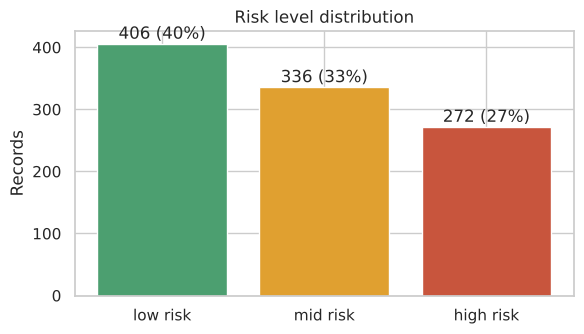

In [11]:
fig, ax = plt.subplots(figsize=(6, 3.5))
counts = df["RiskLevel"].value_counts().reindex(CLASSES)
ax.bar(counts.index, counts.values, color=[PALETTE[c] for c in CLASSES])
for i, v in enumerate(counts.values):
    ax.text(i, v + 8, f"{v} ({v / len(df):.0%})", ha="center")
ax.set_title("Risk level distribution")
ax.set_ylabel("Records")
plt.tight_layout()
plt.show()

The classes are only **mildly imbalanced** (40% / 33% / 27%), which matters for how we handle imbalance in Section 8.

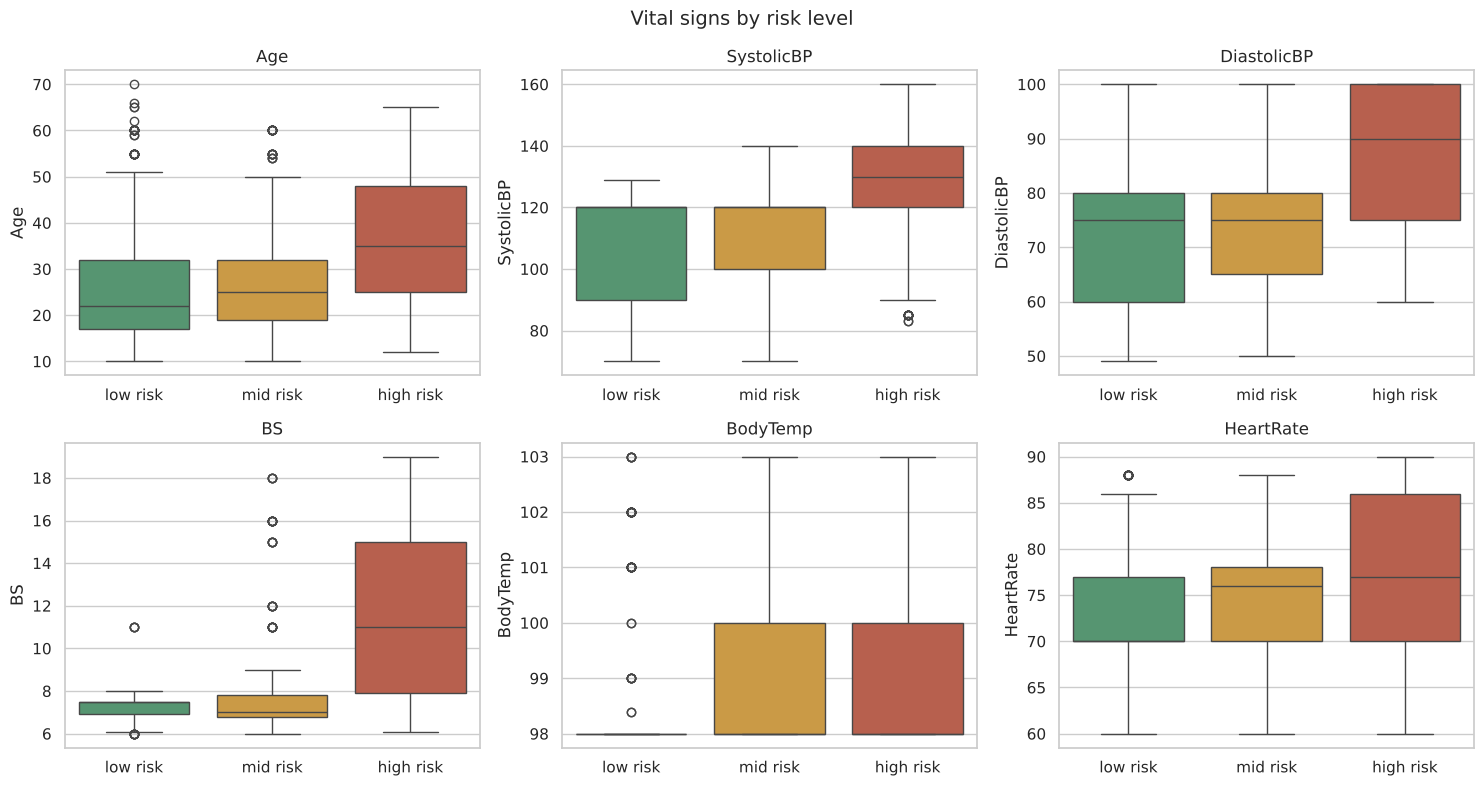

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(data=df, x="RiskLevel", y=col, order=CLASSES, palette=PALETTE, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Vital signs by risk level", fontsize=14)
plt.tight_layout()
plt.show()

In [13]:
summary = df.groupby("RiskLevel")[FEATURES].median().reindex(CLASSES)
summary

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
RiskLevel,,,,,,
low risk,22.0,120.0,75.0,7.5,98.0,70.0
mid risk,25.0,120.0,75.0,7.0,98.0,76.0
high risk,35.0,130.0,90.0,11.0,98.0,77.0


**Observations**

- **Blood glucose** separates high risk cases most clearly: most low and mid risk readings sit around 6 to 8 mmol/L, while high risk cases often exceed 10 mmol/L.
- **Systolic and diastolic blood pressure** rise with risk level; most high risk cases are at or above the 140/90 hypertension threshold.
- **Age** is higher on average in the high risk group.
- **Body temperature** is 98 °F for most records, but fever readings appear more often in higher risk groups.
- **Low and mid risk overlap heavily** on every feature, so we should expect most errors to happen between these two classes.

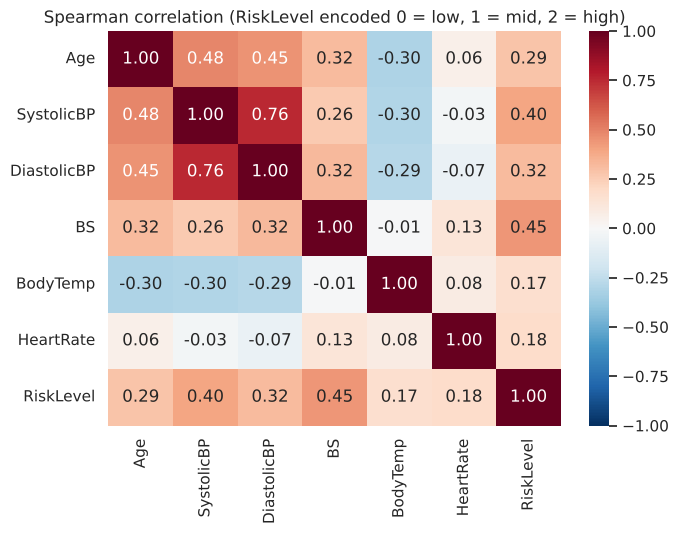

In [14]:
corr = df[FEATURES].assign(RiskLevel=y).corr(method="spearman")
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation (RiskLevel encoded 0 = low, 1 = mid, 2 = high)")
plt.tight_layout()
plt.show()

Systolic and diastolic pressure are strongly correlated with each other, which is expected. Spearman correlation is used because the target is ordinal and several features are skewed.

## 5. Clinical Feature Engineering

Raw readings are combined into indicators that clinicians actually use.

| New feature | Definition | Why |
|---|---|---|
| PulsePressure | Systolic minus diastolic | Reflects arterial stiffness |
| MAP | Mean arterial pressure: diastolic + (systolic − diastolic) / 3 | Overall perfusion pressure |
| Hypertension | Systolic ≥ 140 or diastolic ≥ 90 | Standard threshold for hypertension in pregnancy |
| HighBS | Blood glucose ≥ 7.8 mmol/L | Elevated glucose threshold |
| Fever | Temperature ≥ 100.4 °F | Standard fever threshold |
| AgeRisk | Age under 18 or over 35 | Teenage and advanced maternal age carry higher risk |

These features are computed row by row and learn nothing from the data, so they cannot leak information between training and test sets.

In [15]:
def add_clinical_features(X):
    """Add indicators derived from the six vital signs using fixed clinical thresholds."""
    X = X.copy()
    X["PulsePressure"] = X["SystolicBP"] - X["DiastolicBP"]
    X["MAP"] = X["DiastolicBP"] + (X["SystolicBP"] - X["DiastolicBP"]) / 3
    X["Hypertension"] = ((X["SystolicBP"] >= 140) | (X["DiastolicBP"] >= 90)).astype(int)
    X["HighBS"] = (X["BS"] >= 7.8).astype(int)
    X["Fever"] = (X["BodyTemp"] >= 100.4).astype(int)
    X["AgeRisk"] = ((X["Age"] < 18) | (X["Age"] > 35)).astype(int)
    return X

add_clinical_features(X.head())

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,PulsePressure,MAP,Hypertension,HighBS,Fever,AgeRisk
0,25,130,80,15.0,98.0,86.0,50,96.666667,0,1,0,0
1,35,140,90,13.0,98.0,70.0,50,106.666667,1,1,0,0
2,29,90,70,8.0,100.0,80.0,20,76.666667,0,1,0,0
3,30,140,85,7.0,98.0,70.0,55,103.333333,1,0,0,0
4,35,120,60,6.1,98.0,76.0,60,80.000000,0,0,0,0


## 6. Evaluation Design: Why the Split Matters

We hold out **20% of the groups** as a final test set that is used only once, at the very end. All model comparisons happen with cross validation on the remaining 80%.

Every split uses `StratifiedGroupKFold`, which keeps each group of identical readings on one side of the split while preserving the class balance.

In [16]:
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(outer.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
groups_train = groups[train_idx]

print(f"Training records: {len(train_idx)} | Test records: {len(test_idx)}")
print(f"Groups shared between train and test: {len(set(groups[train_idx]) & set(groups[test_idx]))}")
print("Test class distribution:", np.round(np.bincount(y_test) / len(y_test), 3))

Training records: 811 | Test records: 203
Groups shared between train and test: 0
Test class distribution: [0.404 0.325 0.271]


**Metrics**

- **Macro F1** (primary): averages F1 over the three classes equally, so the smaller high risk class counts as much as the larger low risk class.
- **Balanced accuracy**: average recall per class.
- **High risk recall**: the share of truly high risk patients the model flags as high risk.

To reduce the noise of a single split on a small dataset, cross validation is **repeated 3 times with different shuffles** (15 folds in total) and reported as mean ± standard deviation.

In [17]:
SCORING = {
    "macro_f1": "f1_macro",
    "balanced_acc": "balanced_accuracy",
    "high_risk_recall": make_scorer(recall_score, labels=[2], average="macro"),
}

def grouped_cv(model, X=X_train, y=y_train, groups=groups_train, repeats=3):
    """Repeated stratified group k-fold. Returns mean and std of each metric."""
    fold_means = []
    for r in range(repeats):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + r)
        scores = cross_validate(model, X, y, groups=groups, cv=cv, scoring=SCORING)
        fold_means.append({m: scores[f"test_{m}"].mean() for m in SCORING})
    fold_means = pd.DataFrame(fold_means)
    return pd.Series({**{f"{m}": fold_means[m].mean() for m in SCORING},
                      **{f"{m}_std": fold_means[m].std() for m in SCORING}})

def fmt(results):
    """Format a results table as 'mean ± std'."""
    out = pd.DataFrame(index=results.index)
    for m in SCORING:
        out[m] = results[m].map("{:.3f}".format) + " ± " + results[f"{m}_std"].map("{:.3f}".format)
    return out

### Experiment: what happens with an ordinary random split?

The same Random Forest is evaluated twice: once with a standard random `StratifiedKFold`, where identical readings can fall on both sides, and once with the grouped split used in this project.

In [18]:
def make_rf(class_weight="balanced"):
    return Pipeline([
        ("features", FunctionTransformer(add_clinical_features)),
        ("impute", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=300, class_weight=class_weight, random_state=RANDOM_STATE)),
    ])

naive_scores = []
for r in range(3):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + r)
    s = cross_validate(make_rf(), X_train, y_train, cv=cv, scoring=SCORING)
    naive_scores.append({m: s[f"test_{m}"].mean() for m in SCORING})
naive = pd.DataFrame(naive_scores)
naive = pd.Series({**naive.mean().to_dict(), **{f"{m}_std": naive[m].std() for m in SCORING}})

leakage = pd.DataFrame({"Random split (leaky)": naive, "Grouped split (honest)": grouped_cv(make_rf())}).T
fmt(leakage)

,macro_f1,balanced_acc,high_risk_recall
Random split (leaky),0.836 ± 0.011,0.840 ± 0.011,0.902 ± 0.015
Grouped split (honest),0.632 ± 0.016,0.650 ± 0.008,0.805 ± 0.024


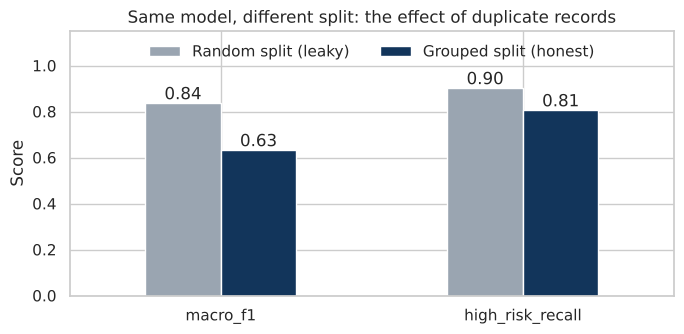

In [19]:
fig, ax = plt.subplots(figsize=(7, 3.5))
vals = leakage[["macro_f1", "high_risk_recall"]]
vals.T.plot.bar(ax=ax, color=["#9AA5B1", "#12355B"], rot=0)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Score")
ax.set_title("Same model, different split: the effect of duplicate records")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f")
ax.legend(loc="upper center", ncol=2, frameon=False)
plt.tight_layout()
plt.show()

**This is the most important result in the notebook.** With a random split, the model appears to reach a macro F1 above 0.8. With the grouped split, it drops by about 0.2. The difference is not better learning: under a random split, many test records are exact copies of training records, so the model is partly graded on memorized answers.

**All results from here on use the grouped split**, so they estimate performance on genuinely new patients.

## 7. Model Comparison

Four models are compared, from simplest to most flexible:

- **Dummy baseline:** guesses according to the class proportions. Any useful model must clearly beat it.
- **Logistic Regression:** linear and easy to interpret; needs scaled features.
- **Random Forest:** an ensemble of decision trees that captures non linear patterns.
- **Histogram Gradient Boosting:** builds trees sequentially, each one correcting the previous ones' errors; often the strongest choice for tabular data.

Each model is evaluated with and without the clinical features. All preprocessing sits inside a `Pipeline`, so imputation and scaling are learned from the training folds only.

In [20]:
def make_model(name, class_weight="balanced", clinical=True):
    steps = [("features", FunctionTransformer(add_clinical_features))] if clinical else []
    steps.append(("impute", SimpleImputer(strategy="median")))
    if name == "Dummy":
        steps.append(("model", DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)))
    elif name == "Logistic Regression":
        steps += [("scale", StandardScaler()),
                  ("model", LogisticRegression(max_iter=2000, class_weight=class_weight))]
    elif name == "Random Forest":
        steps.append(("model", RandomForestClassifier(n_estimators=300, class_weight=class_weight,
                                                      random_state=RANDOM_STATE)))
    elif name == "Gradient Boosting":
        steps.append(("model", HistGradientBoostingClassifier(class_weight=class_weight,
                                                              random_state=RANDOM_STATE)))
    return Pipeline(steps)

MODELS = ["Dummy", "Logistic Regression", "Random Forest", "Gradient Boosting"]
rows = {}
for name in MODELS:
    rows[(name, "raw features")] = grouped_cv(make_model(name, clinical=False))
    if name != "Dummy":
        rows[(name, "+ clinical features")] = grouped_cv(make_model(name, clinical=True))

comparison = pd.DataFrame(rows).T
fmt(comparison)

macro_f1   balanced_acc  \
Dummy               raw features         0.325 ± 0.011  0.329 ± 0.010   
Logistic Regression raw features         0.618 ± 0.006  0.624 ± 0.007   
                    + clinical features  0.616 ± 0.007  0.628 ± 0.010   
Random Forest       raw features         0.634 ± 0.025  0.655 ± 0.021   
                    + clinical features  0.632 ± 0.016  0.650 ± 0.008   
Gradient Boosting   raw features         0.638 ± 0.019  0.656 ± 0.014   
                    + clinical features  0.657 ± 0.026  0.674 ± 0.024   

                                        high_risk_recall  
Dummy               raw features           0.177 ± 0.012  
Logistic Regression raw features           0.736 ± 0.017  
                    + clinical features    0.730 ± 0.032  
Random Forest       raw features           0.830 ± 0.020  
                    + clinical features    0.805 ± 0.024  
Gradient Boosting   raw features           0.814 ± 0.019  
                    + clinical features    0.833 ± 0.031

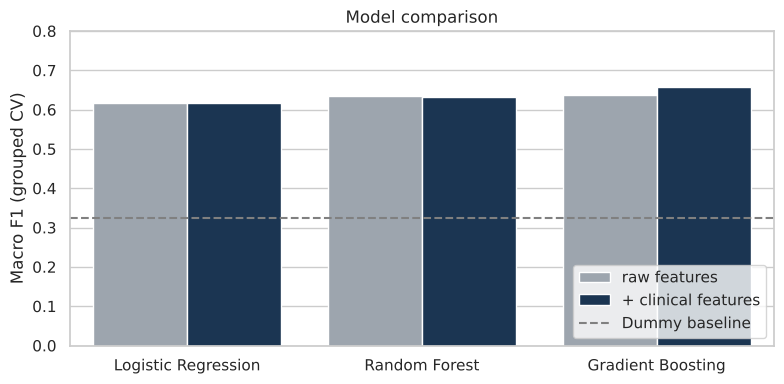

In [21]:
plot_df = comparison.reset_index().rename(columns={"level_0": "model", "level_1": "features"})
plot_df = plot_df[plot_df["model"] != "Dummy"]
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=plot_df, x="model", y="macro_f1", hue="features", palette=["#9AA5B1", "#12355B"], ax=ax)
ax.axhline(comparison.loc[("Dummy", "raw features"), "macro_f1"], ls="--", c="grey", label="Dummy baseline")
ax.set_ylim(0, 0.8)
ax.set_ylabel("Macro F1 (grouped CV)")
ax.set_xlabel("")
ax.legend(loc="lower right")
ax.set_title("Model comparison")
plt.tight_layout()
plt.show()

**Takeaways**

- Every model beats the dummy baseline by a wide margin, so the vital signs carry real signal.
- **Gradient Boosting with clinical features performs best** on macro F1 and high risk recall.
- The clinical features give Gradient Boosting a small gain, while the other models stay about the same.
- Differences between models are modest relative to the standard deviations, which is normal for a dataset with about 400 unique readings. We should be careful not to over interpret small gaps.

Gradient Boosting with clinical features is carried forward.

## 8. Handling Class Imbalance: Class Weights vs SMOTE

Three strategies are compared, all inside the cross validation loop:

1. **None:** train on the data as is.
2. **Class weights:** errors on smaller classes cost more during training. No data is added.
3. **SMOTE:** creates synthetic examples of the smaller classes. It is applied **inside the pipeline**, so synthetic records are generated from the training folds only and never appear in validation data.

In [22]:
def make_smote(name):
    base = make_model(name, class_weight=None, clinical=True)
    steps = base.steps[:-1] + [("smote", SMOTE(random_state=RANDOM_STATE)), base.steps[-1]]
    return ImbPipeline(steps)

rows = {}
for name in ["Logistic Regression", "Random Forest", "Gradient Boosting"]:
    rows[(name, "none")] = grouped_cv(make_model(name, class_weight=None))
    rows[(name, "class weights")] = grouped_cv(make_model(name, class_weight="balanced"))
    rows[(name, "SMOTE")] = grouped_cv(make_smote(name))

imbalance = pd.DataFrame(rows).T
fmt(imbalance)

macro_f1   balanced_acc  \
Logistic Regression none           0.616 ± 0.013  0.624 ± 0.015   
                    class weights  0.616 ± 0.007  0.628 ± 0.010   
                    SMOTE          0.614 ± 0.003  0.623 ± 0.008   
Random Forest       none           0.632 ± 0.008  0.650 ± 0.007   
                    class weights  0.632 ± 0.016  0.650 ± 0.008   
                    SMOTE          0.641 ± 0.013  0.660 ± 0.005   
Gradient Boosting   none           0.659 ± 0.029  0.674 ± 0.026   
                    class weights  0.657 ± 0.026  0.674 ± 0.024   
                    SMOTE          0.650 ± 0.016  0.668 ± 0.009   

                                  high_risk_recall  
Logistic Regression none             0.666 ± 0.033  
                    class weights    0.730 ± 0.032  
                    SMOTE            0.704 ± 0.026  
Random Forest       none             0.796 ± 0.025  
                    class weights    0.805 ± 0.024  
                    SMOTE            0.818 ± 0.016  
Gradient Boosting   none             0.830 ± 0.032  
                    class weights    0.833 ± 0.031  
                    SMOTE            0.827 ± 0.010

**Takeaways**

- With only mild imbalance, **no strategy clearly wins**; the differences are within one standard deviation.
- SMOTE does not improve on class weights, and it adds synthetic patients whose readings may not be clinically realistic.
- **Class weights are kept** for the final model: they are simpler, add no artificial data, and keep high risk recall high.

## 9. Hyperparameter Tuning

The Gradient Boosting pipeline is tuned with a randomized search. The search uses the same grouped cross validation, so tuning never sees records that are duplicated in its validation folds. The test set is still untouched.

In [23]:
param_distributions = {
    "model__learning_rate": [0.02, 0.05, 0.1, 0.2],
    "model__max_iter": [100, 200, 400],
    "model__max_depth": [None, 3, 5, 8],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [5, 10, 20, 40],
    "model__l2_regularization": [0.0, 0.1, 1.0],
}

search = RandomizedSearchCV(
    make_model("Gradient Boosting"),
    param_distributions,
    n_iter=40,
    scoring="f1_macro",
    cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
search.fit(X_train, y_train, groups=groups_train)

print("Best parameters:")
for k, v in search.best_params_.items():
    print(f"  {k.replace('model__', '')}: {v}")

Best parameters:
  min_samples_leaf: 5
  max_leaf_nodes: 31
  max_iter: 400
  max_depth: 3
  learning_rate: 0.1
  l2_regularization: 0.0


In [24]:
default_gb = comparison.loc[("Gradient Boosting", "+ clinical features")]
tuned_gb = grouped_cv(search.best_estimator_)
fmt(pd.DataFrame({"Default": default_gb, "Tuned": tuned_gb}).T)

,macro_f1,balanced_acc,high_risk_recall
Default,0.657 ± 0.026,0.674 ± 0.024,0.833 ± 0.031
Tuned,0.663 ± 0.028,0.677 ± 0.021,0.833 ± 0.007


Tuning is checked with the same repeated grouped cross validation, not with the single score from the search itself, because the best score of a search is optimistically biased. Whichever version scores higher here becomes the final model.

In [25]:
use_tuned = tuned_gb["macro_f1"] >= default_gb["macro_f1"]
final_model = search.best_estimator_ if use_tuned else make_model("Gradient Boosting")
print("Final model:", "tuned" if use_tuned else "default", "Gradient Boosting")
final_model.fit(X_train, y_train)

Final model: tuned Gradient Boosting


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('impute', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Age','SystolicBP','DiastolicBP','BS','BodyTemp','HeartRate']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...x7ff04f239620>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


## 10. Other Approaches Tried

Before touching the test set, several ideas for improving the model were tested with the same repeated grouped cross validation. Each one targets a specific weakness found so far.

| Approach | Idea |
|---|---|
| Inverse group weights | Weight each record by 1 / (number of identical copies), so every unique reading counts equally in training |
| Ordinal model | Risk levels are ordered, so predict *P(risk above low)* and *P(risk above mid)* with two binary models |
| Ordinal + monotonic constraints | Force the model so that higher blood pressure, glucose, or temperature can never *lower* the predicted risk |
| Extra Trees | A more randomized tree ensemble |
| Soft voting ensemble | Average the probabilities of Logistic Regression, Random Forest, and Gradient Boosting |
| Tuned decision thresholds | Rescale class probabilities to favour mid risk, with the scaling learned inside each training fold |

In [26]:
BEST_PARAMS = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
INCREASING = {"Age": 0, "SystolicBP": 1, "DiastolicBP": 1, "BS": 1, "BodyTemp": 1, "HeartRate": 1,
              "PulsePressure": 0, "MAP": 1, "Hypertension": 1, "HighBS": 1, "Fever": 1, "AgeRisk": 1}

def make_gb(**extra):
    return Pipeline([
        ("features", FunctionTransformer(add_clinical_features)),
        ("impute", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE,
                                                 **{**BEST_PARAMS, **extra})),
    ])


class OrdinalClassifier(BaseEstimator, ClassifierMixin):
    """Frank and Hall ordinal classifier built from two binary Gradient Boosting models."""

    def __init__(self, monotonic=False):
        self.monotonic = monotonic

    def fit(self, X, y, sample_weight=None):
        columns = add_clinical_features(X.head(1)).columns
        constraints = [INCREASING[c] for c in columns] if self.monotonic else None
        self.models_ = [make_gb(monotonic_cst=constraints).fit(X, (y > k).astype(int),
                                                                model__sample_weight=sample_weight)
                        for k in (0, 1)]
        self.classes_ = np.array([0, 1, 2])
        return self

    def predict_proba(self, X):
        p_above_low = self.models_[0].predict_proba(X)[:, 1]
        p_above_mid = np.minimum(self.models_[1].predict_proba(X)[:, 1], p_above_low)
        return np.column_stack([1 - p_above_low, p_above_low - p_above_mid, p_above_mid])

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)


class ThresholdTunedClassifier(BaseEstimator, ClassifierMixin):
    """Rescales class probabilities with multipliers learned by inner grouped cross validation."""

    def fit(self, X, y, groups=None):
        oof = np.zeros((len(y), 3))
        inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
        for a, b in inner.split(X, y, groups):
            oof[b] = make_gb().fit(X.iloc[a], y[a]).predict_proba(X.iloc[b])
        grid = [(m, h) for m in np.arange(0.8, 2.6, 0.1) for h in np.arange(0.6, 1.6, 0.1)]
        best = max(grid, key=lambda w: f1_score(y, (oof * [1, *w]).argmax(axis=1), average="macro"))
        self.multipliers_ = np.array([1, *best])
        self.model_ = make_gb().fit(X, y)
        self.classes_ = np.array([0, 1, 2])
        return self

    def predict_proba(self, X):
        p = self.model_.predict_proba(X) * self.multipliers_
        return p / p.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

In [27]:
def grouped_cv_params(model, params, repeats=3):
    """Same as grouped_cv, but passes extra fit parameters (sample weights or groups)."""
    fold_means = []
    for r in range(repeats):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + r)
        scores = cross_validate(model, X_train, y_train, groups=groups_train, cv=cv,
                                scoring=SCORING, params=params)
        fold_means.append({m: scores[f"test_{m}"].mean() for m in SCORING})
    fold_means = pd.DataFrame(fold_means)
    return pd.Series({**{m: fold_means[m].mean() for m in SCORING},
                      **{f"{m}_std": fold_means[m].std() for m in SCORING}})

group_sizes = pd.Series(groups_train).map(pd.Series(groups_train).value_counts()).values
inverse_weights = 1.0 / group_sizes

voting = VotingClassifier([
    ("lr", make_model("Logistic Regression")),
    ("rf", make_model("Random Forest")),
    ("gb", make_gb()),
], voting="soft")

extra_trees = Pipeline([
    ("features", FunctionTransformer(add_clinical_features)),
    ("impute", SimpleImputer(strategy="median")),
    ("model", ExtraTreesClassifier(n_estimators=500, min_samples_leaf=2, class_weight="balanced",
                                   random_state=RANDOM_STATE)),
])

attempts = pd.DataFrame({
    "Final model (tuned Gradient Boosting)": tuned_gb,
    "Inverse group weights": grouped_cv_params(make_gb(), {"model__sample_weight": inverse_weights}),
    "Ordinal model": grouped_cv(OrdinalClassifier()),
    "Ordinal + monotonic constraints": grouped_cv(OrdinalClassifier(monotonic=True)),
    "Extra Trees": grouped_cv(extra_trees),
    "Soft voting ensemble": grouped_cv(voting),
    "Tuned decision thresholds": grouped_cv_params(ThresholdTunedClassifier(), {"groups": groups_train}),
}).T
fmt(attempts)

,macro_f1,balanced_acc,high_risk_recall
Final model (tuned Gradient Boosting),0.663 ± 0.028,0.677 ± 0.021,0.833 ± 0.007
Inverse group weights,0.638 ± 0.030,0.655 ± 0.023,0.805 ± 0.017
Ordinal model,0.648 ± 0.007,0.666 ± 0.005,0.816 ± 0.014
Ordinal + monotonic constraints,0.643 ± 0.011,0.661 ± 0.007,0.833 ± 0.014
Extra Trees,0.613 ± 0.018,0.630 ± 0.014,0.767 ± 0.011
Soft voting ensemble,0.660 ± 0.023,0.677 ± 0.015,0.839 ± 0.012
Tuned decision thresholds,0.668 ± 0.028,0.680 ± 0.024,0.824 ± 0.011


**Takeaways**

- **No approach clearly beats the tuned Gradient Boosting model.** Tuned decision thresholds score marginally higher on macro F1 (by about 0.005, far less than one standard deviation) while slightly lowering high risk recall, and the soft voting ensemble performs about the same. Neither gain justifies the extra complexity.
- The other ideas, including the ordinal model with monotonic constraints and inverse group weights, perform worse.
- This points to the **data, not the algorithm, as the limiting factor:** low and mid risk overlap on every vital sign, and some identical readings carry different labels (Section 3). Better performance would need additional information, such as medical history or gestational age.

The tuned Gradient Boosting model is kept as the final model.

## 11. Final Evaluation on the Held Out Test Set

The test set has been untouched until now and is used exactly once.

In [28]:
y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)

test_results = pd.Series({
    "Macro F1": f1_score(y_test, y_pred, average="macro"),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Accuracy": (y_pred == y_test).mean(),
    "High risk recall": recall_score(y_test, y_pred, labels=[2], average="macro"),
    "ROC AUC (one vs rest, macro)": roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro"),
}).round(3)
test_results

Macro F1                        0.605
Balanced accuracy               0.623
Accuracy                        0.640
High risk recall                0.764
ROC AUC (one vs rest, macro)    0.812
dtype: float64

In [29]:
print(classification_report(y_test, y_pred, target_names=CLASSES, digits=3))

              precision    recall  f1-score   support

    low risk      0.570     0.939     0.710        82
    mid risk      0.423     0.167     0.239        66
   high risk      1.000     0.764     0.866        55

    accuracy                          0.640       203
   macro avg      0.664     0.623     0.605       203
weighted avg      0.639     0.640     0.599       203



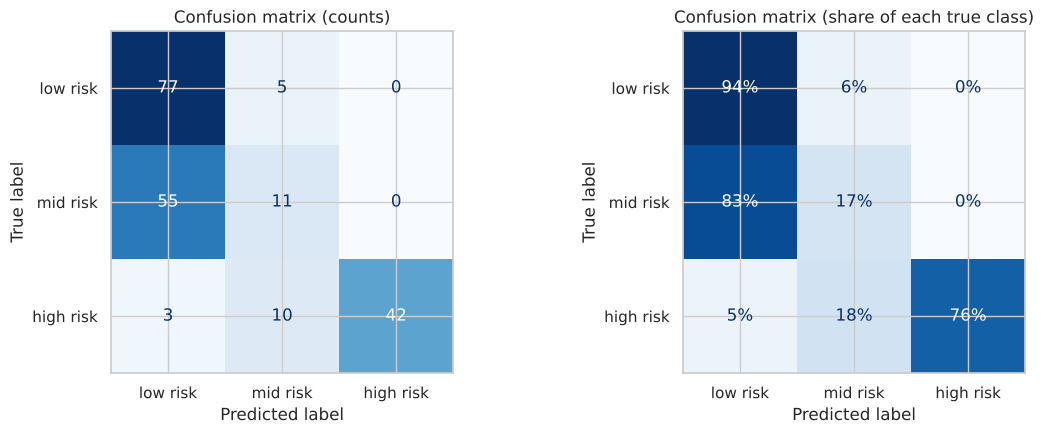

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASSES, cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASSES, cmap="Blues", ax=axes[1],
                                        normalize="true", values_format=".0%", colorbar=False)
axes[1].set_title("Confusion matrix (share of each true class)")
plt.tight_layout()
plt.show()

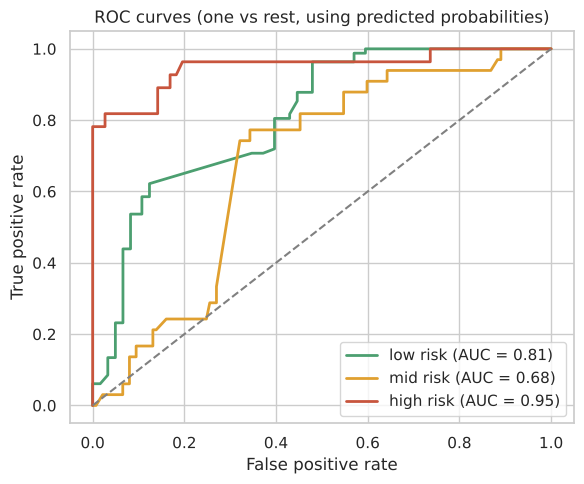

In [31]:
fig, ax = plt.subplots(figsize=(6, 5))
for i, cls in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve((y_test == i).astype(int), y_proba[:, i])
    auc_i = roc_auc_score((y_test == i).astype(int), y_proba[:, i])
    ax.plot(fpr, tpr, color=PALETTE[cls], lw=2, label=f"{cls} (AUC = {auc_i:.2f})")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right")
ax.plot([0, 1], [0, 1], "--", c="grey")
ax.set_title("ROC curves (one vs rest, using predicted probabilities)")
plt.tight_layout()
plt.show()

ROC curves are computed from the model's **predicted probabilities**, not from hard class labels. This is what lets the curve trace out every possible decision threshold.

**Reading the results**

- **High risk is handled well:** every patient the model flags as high risk truly is (precision 1.00), and it catches about three quarters of them.
- **Mid risk is the weak spot:** most mid risk patients are predicted as low risk.
- The test macro F1 is a little lower than the cross validation estimate. Sections 12 and 14 show that a single record, repeated many times in the test set, explains much of this gap.

## 12. Robustness Check: Without Duplicates

Does the conclusion depend on keeping the duplicate records? Two checks:

1. **Same model, deduplicated test set:** each unique test reading counted once, so frequent records do not dominate the score.
2. **Retrained on deduplicated data:** a fresh model with the same settings, trained and tested on unique records only.

In [32]:
test_df = X_test.assign(y=y_test, pred=y_pred).drop_duplicates()
dedup_test = {
    "Macro F1": f1_score(test_df["y"], test_df["pred"], average="macro"),
    "High risk recall": recall_score(test_df["y"], test_df["pred"], labels=[2], average="macro"),
}

train_unique = X_train.assign(y=y_train).drop_duplicates()
model_unique = clone(final_model)
model_unique.fit(train_unique[FEATURES], train_unique["y"])
pred_unique = model_unique.predict(test_df[FEATURES])
dedup_retrain = {
    "Macro F1": f1_score(test_df["y"], pred_unique, average="macro"),
    "High risk recall": recall_score(test_df["y"], pred_unique, labels=[2], average="macro"),
}

pd.DataFrame({
    "Full test set": test_results[["Macro F1", "High risk recall"]],
    "Deduplicated test set": dedup_test,
    "Retrained on deduplicated data": dedup_retrain,
}).T.round(3)

,Macro F1,High risk recall
Full test set,0.605,0.764
Deduplicated test set,0.664,0.696
Retrained on deduplicated data,0.669,0.739


**Interpretation:** on unique test readings, macro F1 rises to about 0.66, matching the cross validation estimate from Sections 7 to 9, and a model retrained on deduplicated data performs the same. So the method is robust, and the lower full test score comes from a few heavily repeated records rather than from the decision to keep duplicates. Section 14 identifies the main one.

## 13. What Drives the Predictions?

**Permutation importance** measures how much the test macro F1 drops when one input is randomly shuffled. Because the clinical features are computed inside the pipeline, shuffling a raw vital sign also breaks every feature derived from it, so the importance reflects the full contribution of each measurement.

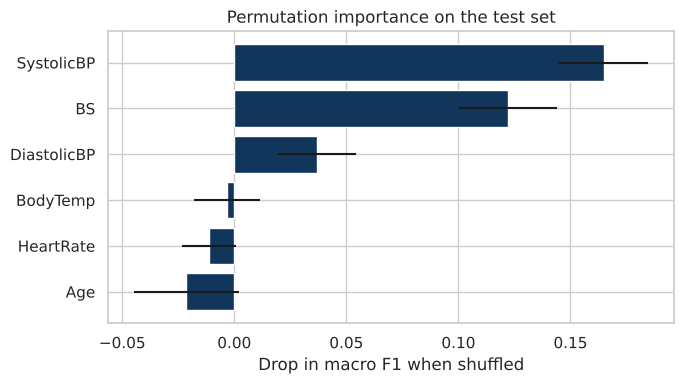

,mean,std
SystolicBP,0.165,0.020
BS,0.122,0.022
DiastolicBP,0.037,0.017
BodyTemp,-0.003,0.015
HeartRate,-0.011,0.012
Age,-0.021,0.023


In [33]:
perm = permutation_importance(final_model, X_test, y_test, scoring="f1_macro",
                              n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                          index=FEATURES).sort_values("mean")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importance.index, importance["mean"], xerr=importance["std"], color="#12355B")
ax.set_xlabel("Drop in macro F1 when shuffled")
ax.set_title("Permutation importance on the test set")
plt.tight_layout()
plt.show()
importance.sort_values("mean", ascending=False).round(3)

## 14. Error Analysis

Which mistakes does the model make, and are they clinically worrying?

In [34]:
errors = X_test.assign(true=[CLASSES[i] for i in y_test], predicted=[CLASSES[i] for i in y_pred])
errors = errors[errors["true"] != errors["predicted"]]

adjacent = (abs(y_test - y_pred) == 1)[y_test != y_pred].mean()
print(f"Misclassified test records: {len(errors)} of {len(y_test)}")
print(f"Errors between neighbouring levels (low/mid or mid/high): {adjacent:.0%}")
print()
print(errors.groupby(["true", "predicted"]).size().rename("count").to_frame())

Misclassified test records: 73 of 203
Errors between neighbouring levels (low/mid or mid/high): 96%

                     count
true      predicted       
high risk low risk       3
          mid risk      10
low risk  mid risk       5
mid risk  low risk      55


In [35]:
# Which readings account for the most errors?
errors.groupby(FEATURES + ["true", "predicted"], dropna=False).size().sort_values(ascending=False).head(5).rename("errors").to_frame()

,,,,,,,,errors
Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,true,predicted,
19,120,80,7.0,98.0,70.0,mid risk,low risk,27
17,120,80,6.7,102.0,76.0,mid risk,low risk,4
23,120,90,7.8,98.0,60.0,mid risk,low risk,3
21,90,60,6.9,98.0,86.0,mid risk,low risk,3
18,90,60,6.9,98.0,70.0,mid risk,low risk,3


In [36]:
# The most frequent error: how is this reading labeled across the whole dataset?
top_error = errors.groupby(FEATURES, dropna=False).size().idxmax()
df.set_index(FEATURES).loc[[top_error], "RiskLevel"].value_counts()

RiskLevel
mid risk    27
low risk     7
Name: count, dtype: int64

In [37]:
# The most serious error: a high risk patient predicted as low risk
missed_high = errors[(errors["true"] == "high risk") & (errors["predicted"] == "low risk")]
print(f"High risk patients predicted as low risk: {len(missed_high)}")
missed_high.drop_duplicates()

High risk patients predicted as low risk: 3


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,true,predicted
135,22,90,60,7.5,102.0,60.0,high risk,low risk
390,17,85,69,7.8,102.0,86.0,high risk,low risk


In [38]:
# How confident is the model when it is right vs wrong?
confidence = pd.DataFrame({"confidence": y_proba.max(axis=1), "correct": y_pred == y_test})
confidence.groupby("correct")["confidence"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
correct,,,,,,,,
False,73.0,0.874,0.127,0.489,0.861,0.893,0.984,1.0
True,130.0,0.928,0.122,0.423,0.893,0.994,1.000,1.0


**Interpretation**

- **Almost all errors are between neighbouring risk levels,** mostly mid risk predicted as low risk. These two classes overlap heavily on every vital sign (Section 4).
- **A single reading explains a large share of the errors.** A 19 year old with completely normal vitals (120/80 mmHg, glucose 7.0 mmol/L, 98 °F, 70 bpm) appears dozens of times in the test set, usually labeled mid risk but sometimes low risk. With normal readings, predicting low risk is a reasonable call; the label likely depends on information the dataset does not contain, such as medical history. This one record is why the full test score sits below the cross validation estimate.
- **The high risk patients predicted as low risk have a fever (102 °F) but otherwise normal readings.** Body temperature has almost no importance in Section 13, so the model under weights fever. Collecting more fever cases, or a rule that flags any fever for review, would be a natural improvement.
- **The model is only slightly less confident when it is wrong,** and many errors are made with high confidence. The probabilities should not be read as certainty.

## 15. Conclusion

- **The evaluation method matters more than the model choice.** A random split overstates macro F1 by about 0.2 because more than half of the records are duplicates. Grouping identical readings gives an honest estimate of performance on new patients.
- **Gradient Boosting with clinical features** performed best, and clearly beats a dummy baseline.
- **Cross validated macro F1 is about 0.66**, and the held out test set confirms it on unique readings. High risk recall is about 0.76 to 0.83, with no false high risk alarms on the test set.
- **High risk patients are caught much more reliably than mid risk ones.** Most errors are mid risk predicted as low risk, driven largely by one heavily repeated record with normal vital signs.
- **Systolic blood pressure and blood glucose** drive the predictions, which matches clinical knowledge, while fever is under used.
- **SMOTE brought no benefit** over class weights for this mildly imbalanced dataset.
- **Six further approaches,** including an ordinal model with monotonic constraints and tuned decision thresholds, did not meaningfully improve on the final model, which points to the data rather than the algorithm as the limiting factor.

### Limitations

- The dataset is small (about 400 unique readings) and comes from a single region, so results may not generalize to other populations.
- Some identical readings carry different labels, which caps achievable performance.
- Only six vital signs are available; medical history, gestational age, and lab tests are missing.
- **This is an educational project and not a clinical tool.** It should never replace a medical assessment.